# Experimento factorial E2 — AbarrotesPOS

**Análisis Estadístico para Ciencia de Datos · Proyecto Integrador TRUSTED DATA LAB · Etapa E2**
Responsable: Ángel Salvador Álvarez Fernández · Equipo: Julio, José Rey, Ángel

**Pregunta del cliente traducida a experimento:** la tienda El Amiguito va a mandarnos sus ventas
cada día. ¿Con qué configuración conviene procesarlas para que el tablero se actualice más rápido?

La tarea que medimos es la misma que hace el pipeline: leer el archivo de tickets, calcular venta
y ganancia por producto y día, y escribir el resultado. Todo corre en local; no toca ningún sitio ajeno.

Este cuaderno **no trae números escritos a mano**: todo sale de los CSV de `laboratorio/resultados/`.
Si se agregan corridas (por ejemplo, el segundo bloque), basta volver a ejecutarlo.

## 1. Diseño

| Factor | Nivel −1 | Nivel +1 | Por qué lo probamos |
|---|---|---|---|
| **A** procesos | 1 proceso | 4 procesos | ¿Paralelizar ayuda con archivos del tamaño de una tienda? |
| **B** tipos | texto | categórico | Las columnas repetidas (producto, forma de pago) podrían ir más rápido como categoría |
| **C** formato | CSV | Parquet | Formato de almacenamiento de la capa plata/oro |
| **D** compresión (solo 2⁴ y 2⁴⁻¹) | sin | con | gzip en CSV, snappy en Parquet |

- **Respuesta principal:** `tiempo_s` (segundos de la corrida). Secundaria: `tamano_mb`.
- **Réplicas:** 3 por tratamiento → 2³ × 3 = 24 corridas.
- **Aleatorización:** el orden de las 24 corridas se baraja con semilla 2026 (columna `orden`),
  para que el calentamiento del equipo no se cargue a un solo tratamiento.
- **Bloque:** la máquina donde se corre (columna `bloque`). La máquina cambia los tiempos pero no nos
  interesa como factor, así que se bloquea.
- **Datos:** los tickets simulados de enero 2025 a octubre 2026 (`pos_demo`, semilla 42; el número exacto lo imprime la celda de abajo) mientras llegan los reales de la tienda.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.graphics.factorplots import interaction_plot
from scipy import stats
from pathlib import Path

RES = Path("resultados") if Path("resultados").exists() else Path("laboratorio/resultados")
pd.set_option("display.precision", 4)
d = pd.read_csv(RES / "corridas_2k3.csv")
print(f"{len(d)} corridas, {d['filas'].iloc[0]:,} tickets por corrida")
print("Corridas por bloque (máquina):")
print(d["bloque"].value_counts().to_string())
d.sort_values("orden").head(8)

24 corridas, 134,889 tickets por corrida
Corridas por bloque (máquina):
bloque
nube-claude    24


,orden,A,B,C,tratamiento,replica,A_nivel,B_nivel,C_nivel,tiempo_s,tamano_mb,bloque,filas
0,1,-1,1,1,4,1,1,categorico,parquet,0.0743,2.165,nube-claude,134889
1,2,1,1,1,8,2,4,categorico,parquet,0.1407,2.165,nube-claude,134889
2,3,-1,1,-1,3,3,1,categorico,csv,0.2811,11.013,nube-claude,134889
3,4,-1,-1,-1,1,3,1,texto,csv,0.2362,11.013,nube-claude,134889
4,5,1,1,-1,7,2,4,categorico,csv,0.4411,11.013,nube-claude,134889
5,6,1,1,1,8,3,4,categorico,parquet,0.1591,2.165,nube-claude,134889
6,7,1,-1,-1,5,1,4,texto,csv,0.4049,11.013,nube-claude,134889
7,8,-1,-1,-1,1,2,1,texto,csv,0.2948,11.013,nube-claude,134889


## 2. ANOVA del 2³

Modelo: `tiempo_s ~ A * B * C` (efectos principales y todas sus interacciones). Si hay más de una
máquina, se agrega el bloque como término aditivo `+ C(bloque)`. Nivel de significancia α = 0.05.

In [2]:
bloques = d["bloque"].nunique()
formula = "tiempo_s ~ A * B * C" + (" + C(bloque)" if bloques > 1 else "")
modelo = smf.ols(formula, data=d).fit()
tabla = anova_lm(modelo, typ=2)
tabla["significativo"] = tabla["PR(>F)"] < 0.05
print("Fórmula:", formula, f"| R² = {modelo.rsquared:.3f}")
if bloques == 1:
    print("Aviso: solo hay un bloque; falta la corrida en la segunda máquina (tarea A2).")
tabla

Fórmula: tiempo_s ~ A * B * C | R² = 0.976
Aviso: solo hay un bloque; falta la corrida en la segunda máquina (tarea A2).


,sum_sq,df,F,PR(>F),significativo
A,8.0632e-02,1.0,127.5211,4.9365e-09,True
B,5.5510e-05,1.0,0.0878,7.7082e-01,False
A:B,2.3503e-03,1.0,3.7170,7.1802e-02,False
C,3.3387e-01,1.0,528.0232,1.1140e-13,True
A:C,3.9270e-05,1.0,0.0621,8.0637e-01,False
B:C,2.5400e-03,1.0,4.0171,6.2272e-02,False
A:B:C,5.3865e-04,1.0,0.8519,3.6973e-01,False
Residual,1.0117e-02,16.0,NaN,NaN,False


### Efectos

En un 2ᵏ codificado −1/+1, el **efecto** de un factor es 2 × su coeficiente: cuánto cambia el tiempo
al pasar ese factor de −1 a +1. Negativo = hace más rápido.

,efecto_s,p,significativo
C,-0.2359,1.1140e-13,True
A,0.1159,4.9365e-09,True
B:C,-0.0206,6.2272e-02,False
A:B,-0.0198,7.1802e-02,False
A:B:C,-0.0095,3.6973e-01,False
B,0.0030,7.7082e-01,False
A:C,-0.0026,8.0637e-01,False


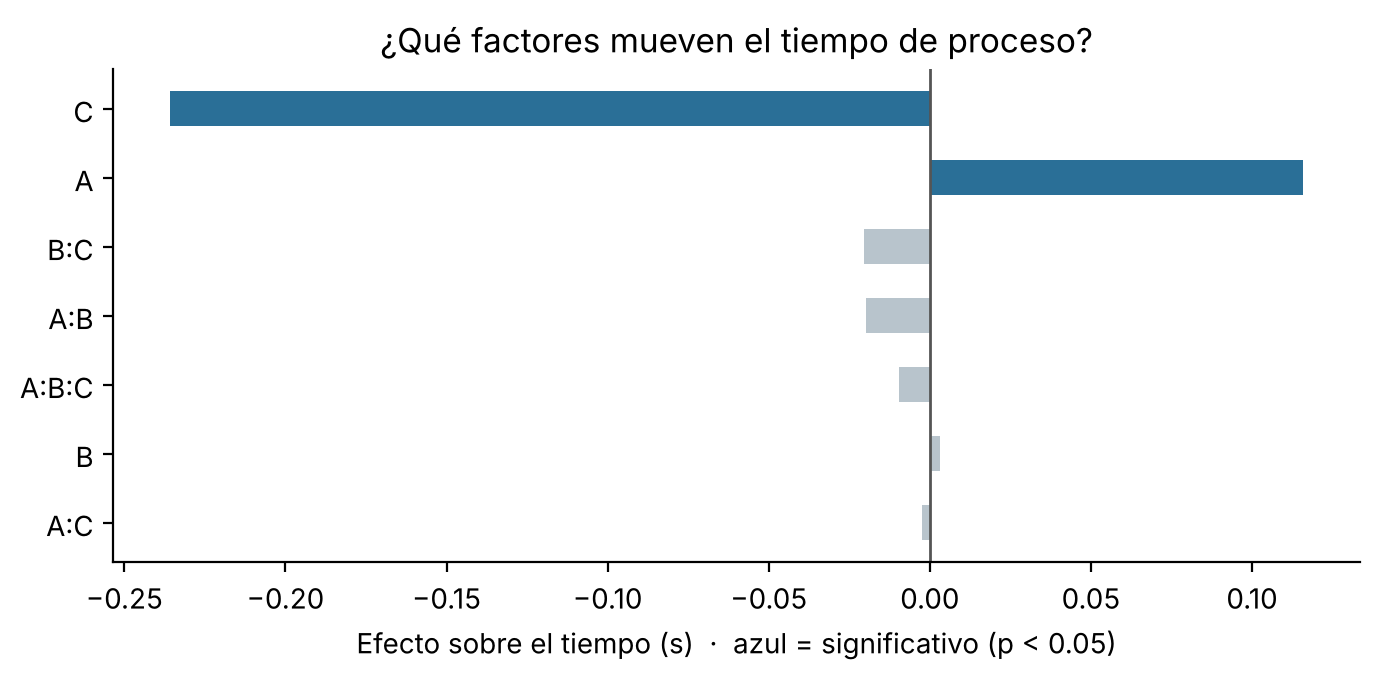

In [3]:
terminos = [t for t in modelo.params.index if t != "Intercept" and not t.startswith("C(bloque)")]
efectos = (2 * modelo.params[terminos]).rename("efecto_s")
pvals = modelo.pvalues[terminos]
resumen = pd.DataFrame({"efecto_s": efectos, "p": pvals, "significativo": pvals < 0.05})
display(resumen.sort_values("efecto_s", key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(7, 3.5))
orden = efectos.reindex(efectos.abs().sort_values().index)
colores = ["#2a6f97" if p < 0.05 else "#b8c4cc" for p in pvals[orden.index]]
ax.barh(orden.index, orden.values, color=colores, height=0.5)
ax.axvline(0, color="#555", lw=1)
ax.set_xlabel("Efecto sobre el tiempo (s)  ·  azul = significativo (p < 0.05)")
ax.set_title("¿Qué factores mueven el tiempo de proceso?")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### Gráficas de interacción

Si las líneas son paralelas, los factores no interactúan: el efecto de uno no depende del otro.

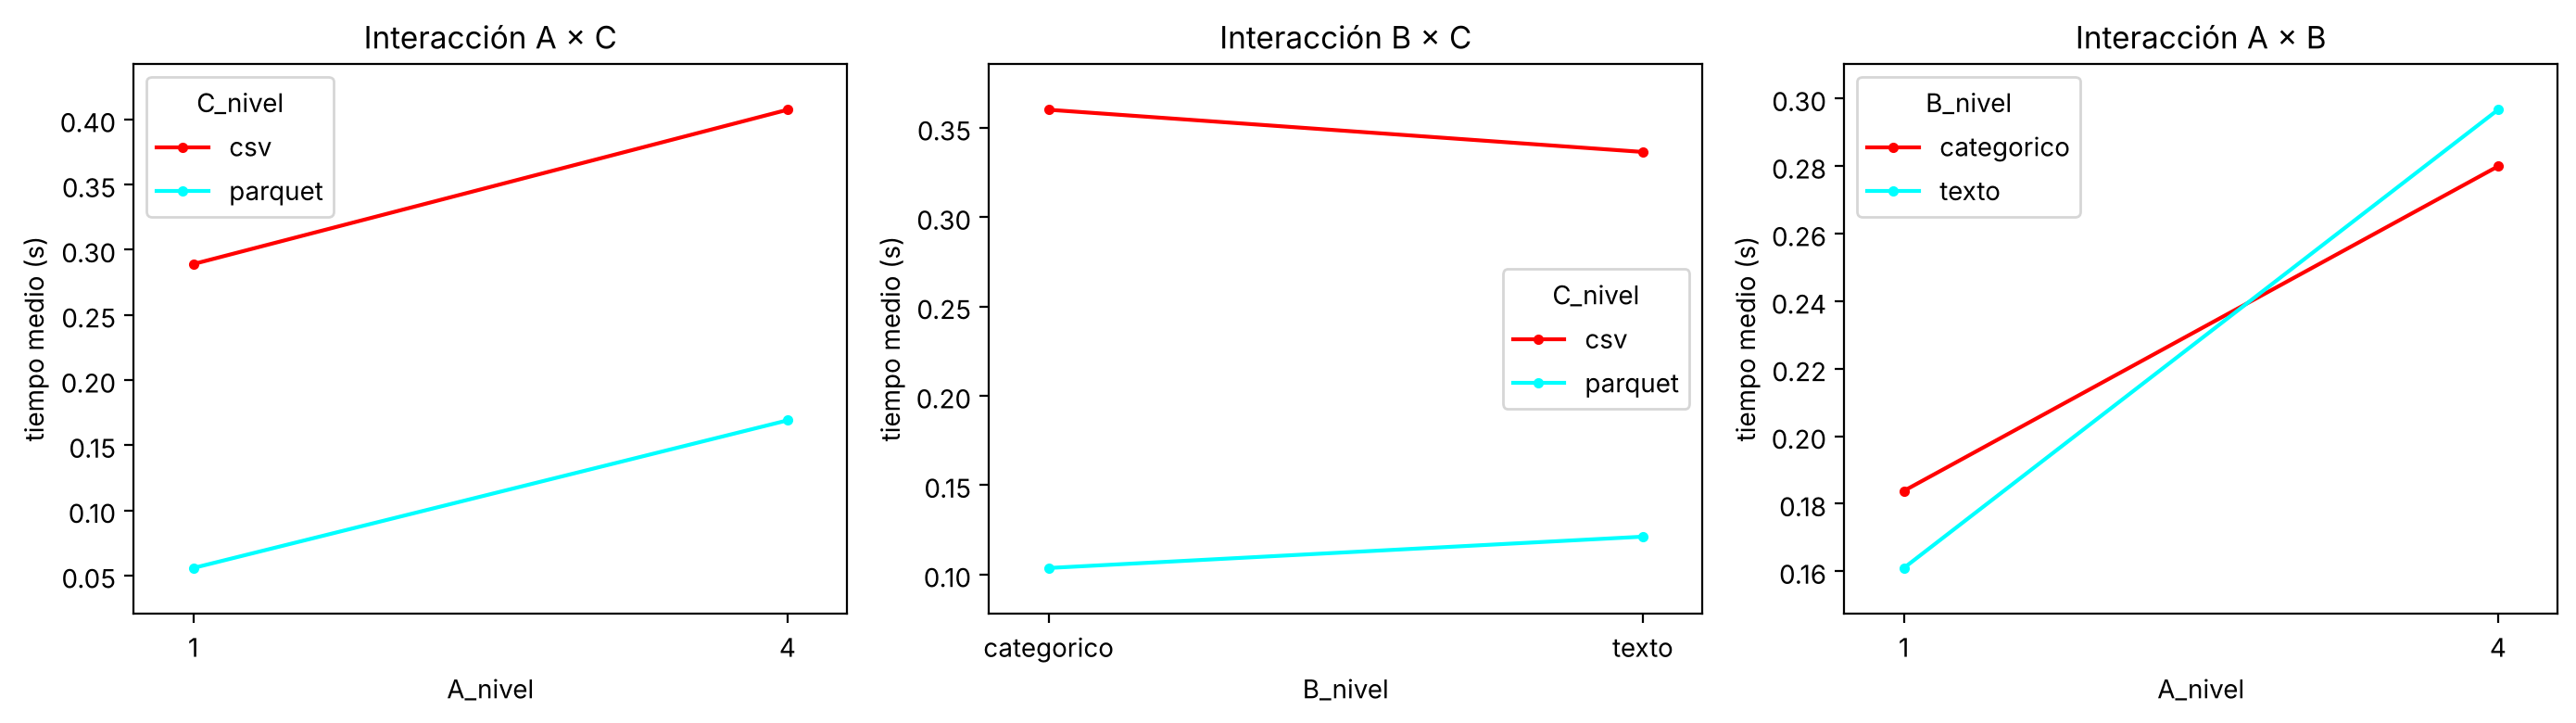

In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (x, traza) in zip(ejes, [("A_nivel", "C_nivel"), ("B_nivel", "C_nivel"), ("A_nivel", "B_nivel")]):
    interaction_plot(d[x].astype(str), d[traza].astype(str), d["tiempo_s"], ax=ax)
    ax.set_title(f"Interacción {x[0]} × {traza[0]}")
    ax.set_ylabel("tiempo medio (s)")
plt.tight_layout(); plt.show()

## 3. Supuestos del ANOVA

- **Normalidad de residuos:** Shapiro-Wilk (H₀: los residuos son normales). Queremos p > 0.05.
- **Varianza constante:** Levene entre los 8 tratamientos (H₀: varianzas iguales). Queremos p > 0.05.
- **Independencia:** la cuida la aleatorización del orden de corridas.

Shapiro-Wilk p = 0.365 -> normalidad OK
Levene       p = 0.772 -> varianzas iguales OK


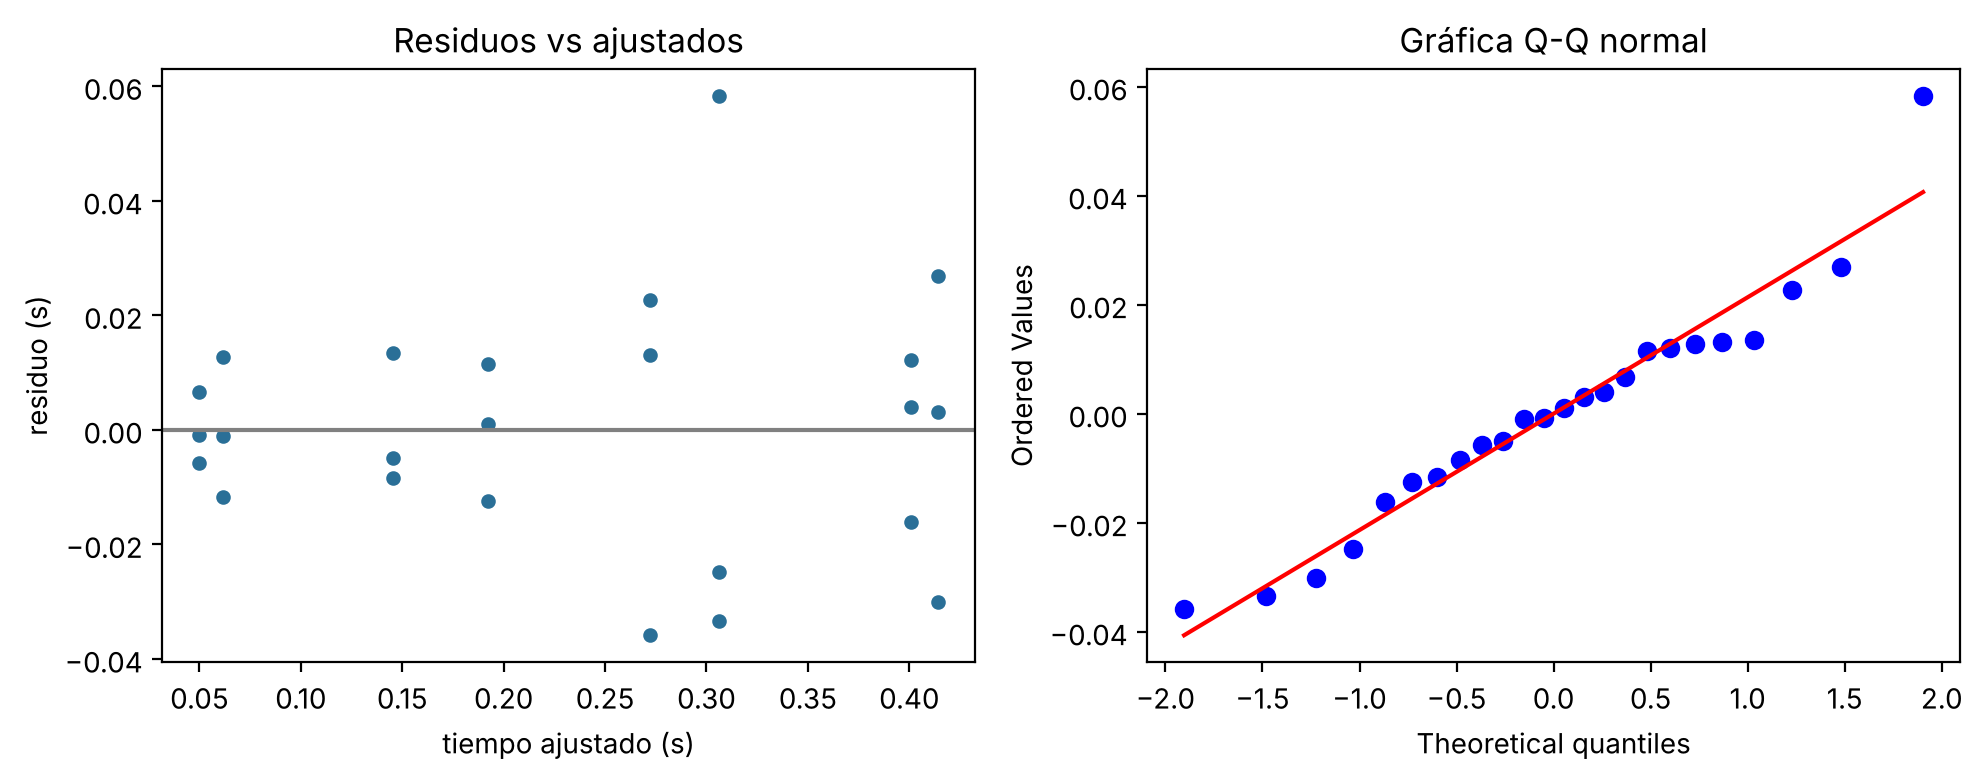

In [5]:
res = modelo.resid
shapiro_p = stats.shapiro(res).pvalue
levene_p = stats.levene(*[g["tiempo_s"] for _, g in d.groupby(["A", "B", "C"])]).pvalue
print(f"Shapiro-Wilk p = {shapiro_p:.3f} -> {'normalidad OK' if shapiro_p > 0.05 else 'NO normal: revisar transformación log'}")
print(f"Levene       p = {levene_p:.3f} -> {'varianzas iguales OK' if levene_p > 0.05 else 'varianzas distintas: revisar'}")

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].scatter(modelo.fittedvalues, res, s=18, color="#2a6f97")
ejes[0].axhline(0, color="gray"); ejes[0].set_title("Residuos vs ajustados")
ejes[0].set_xlabel("tiempo ajustado (s)"); ejes[0].set_ylabel("residuo (s)")
stats.probplot(res, plot=ejes[1]); ejes[1].set_title("Gráfica Q-Q normal")
plt.tight_layout(); plt.show()

## 4. Mejor combinación y corrida de confirmación

El ANOVA dice qué factores importan; la **corrida de confirmación** comprueba que la combinación
ganadora de verdad es más rápida, con corridas nuevas que no se usaron para elegirla.
Se compara contra la configuración actual del pipeline: 1 proceso, texto, CSV.

In [6]:
medias = d.groupby(["A_nivel", "B_nivel", "C_nivel"])["tiempo_s"].agg(["mean", "std", "count"])
display(medias.sort_values("mean"))
optimo = tuple(x.item() if hasattr(x, "item") else x for x in medias["mean"].idxmin())
print("Combinación más rápida (procesos, tipos, formato):", optimo)

conf = pd.read_csv(RES / "confirmacion.csv")
m = conf.groupby("config")["tiempo_s"].agg(["mean", "std", "count"])
display(m)
t = stats.ttest_ind(conf.loc[conf.config == "optimo", "tiempo_s"],
                    conf.loc[conf.config == "actual", "tiempo_s"], equal_var=False)
mejora = 1 - m.loc["optimo", "mean"] / m.loc["actual", "mean"]
print(f"Mejora confirmada: {mejora:.1%} más rápido (t de Welch p = {t.pvalue:.2g})")

mean     std  count
A_nivel B_nivel    C_nivel                       
1       texto      parquet  0.0498  0.0063      3
        categorico parquet  0.0616  0.0122      3
4       categorico parquet  0.1457  0.0118      3
        texto      parquet  0.1925  0.0120      3
1       texto      csv      0.2721  0.0314      3
        categorico csv      0.3060  0.0507      3
4       texto      csv      0.4009  0.0146      3
        categorico csv      0.4142  0.0286      3

Combinación más rápida (procesos, tipos, formato): (1, 'texto', 'parquet')


,mean,std,count
config,,,
actual,0.2436,0.0257,5
optimo,0.0435,0.0110,5


Mejora confirmada: 82.1% más rápido (t de Welch p = 8.9e-06)


## 5. Dos factores con 3 niveles: tamaño × formato

Para ver si la ventaja del formato depende del tamaño del archivo (una tienda crece), cruzamos
**tamaño** (chico = ¼, mediano = ½, grande = todo el histórico) con **formato** (CSV/Parquet),
3 réplicas → 18 corridas. ANOVA de dos vías con interacción.

,sum_sq,df,F,PR(>F),significativo
C(tamano),0.0566,2.0,30.6972,1.9103e-05,True
C(formato),0.1257,1.0,136.3955,6.5387e-08,True
C(tamano):C(formato),0.0367,2.0,19.9253,1.5366e-04,True
Residual,0.0111,12.0,NaN,NaN,False


formato,csv,parquet
tamano,,
chico,0.0878,0.0187
mediano,0.1743,0.0291
grande,0.3323,0.0452


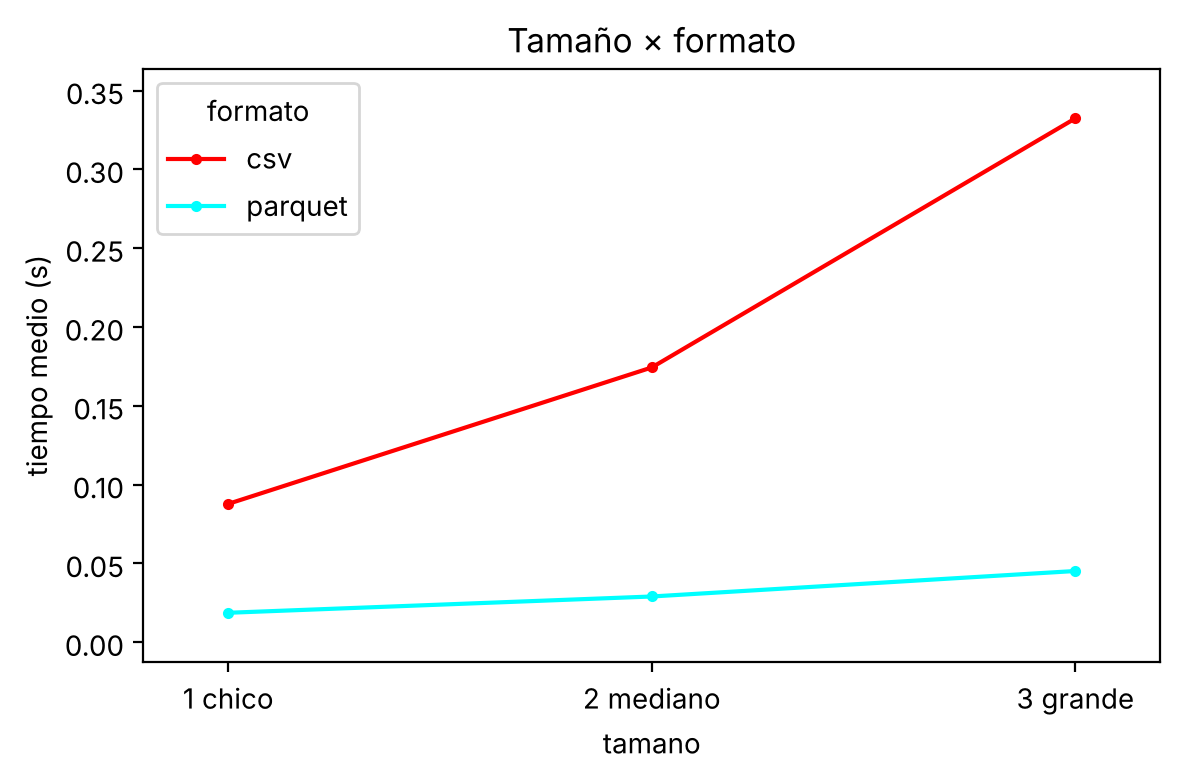

Interacción tamaño × formato: p = 0.0002 -> la ventaja de Parquet CAMBIA con el tamaño


In [7]:
d2 = pd.read_csv(RES / "corridas_dos_factores.csv")
d2["tamano"] = pd.Categorical(d2["tamano"], ["chico", "mediano", "grande"], ordered=True)
m2 = smf.ols("tiempo_s ~ C(tamano) * C(formato)", data=d2).fit()
t2 = anova_lm(m2, typ=2)
t2["significativo"] = t2["PR(>F)"] < 0.05
display(t2)
display(d2.pivot_table(index="tamano", columns="formato", values="tiempo_s", aggfunc="mean", observed=True))
fig, ax = plt.subplots(figsize=(6, 4))
interaction_plot(d2["tamano"].astype(str).map({"chico": "1 chico", "mediano": "2 mediano", "grande": "3 grande"}),
                 d2["formato"], d2["tiempo_s"], ax=ax)
ax.set_title("Tamaño × formato"); ax.set_ylabel("tiempo medio (s)")
plt.tight_layout(); plt.show()
p_int = t2.loc["C(tamano):C(formato)", "PR(>F)"]
print(f"Interacción tamaño × formato: p = {p_int:.4f} ->",
      "la ventaja de Parquet CAMBIA con el tamaño" if p_int < 0.05 else "la ventaja de Parquet es parecida en todos los tamaños")

## 6. Diseño completo 2⁴ contra fraccionado 2⁴⁻¹

Si agregamos el factor **D compresión**, el diseño completo pide 2⁴ = 16 tratamientos por réplica.
El **fraccionado 2⁴⁻¹** usa la mitad (8) definiendo **D = ABC**, o sea la relación definidora
**I = ABCD**. Ahorra 50 % de corridas a cambio de **confundir (aliar)** efectos entre sí.

In [8]:
completo = pd.read_csv(RES / "matriz_2k4_completa.csv")
fracc = pd.read_csv(RES / "matriz_2k4-1_fraccionada.csv")
alias = pd.read_csv(RES / "alias_2k4-1.csv")
print(f"Completo: {len(completo)} tratamientos | Fraccionado: {len(fracc)} | Ahorro: {1 - len(fracc)/len(completo):.0%}")
print("¿Se cumple D = A·B·C en todas las filas del fraccionado?", bool((fracc["D"] == fracc["A"]*fracc["B"]*fracc["C"]).all()))
display(fracc[["tratamiento", "A", "B", "C", "D"]])
display(alias)

Completo: 16 tratamientos | Fraccionado: 8 | Ahorro: 50%
¿Se cumple D = A·B·C en todas las filas del fraccionado? True


,tratamiento,A,B,C,D
0,1,-1,-1,-1,-1
1,2,-1,-1,1,1
2,3,-1,1,-1,1
3,4,-1,1,1,-1
4,5,1,-1,-1,1
5,6,1,-1,1,-1
6,7,1,1,-1,-1
7,8,1,1,1,1


,efecto,confundido_con
0,A,BCD
1,B,ACD
2,C,ABD
3,D,ABC
4,AB,CD
5,AC,BD
6,AD,BC
7,I,ABCD


**Cómo leer los alias.** Multiplicar cualquier efecto por I = ABCD da su alias (una letra al
cuadrado vale 1). Por ejemplo A · ABCD = A²BCD = **BCD**. En el fraccionado, lo que estimamos como
"efecto de A" en realidad es A + BCD.

- **Resolución IV:** los efectos principales solo se confunden con interacciones **triples**, que casi
  nunca importan → los efectos principales salen limpios.
- Las interacciones **dobles** se confunden entre sí (AB con CD, AC con BD, AD con BC) → si una sale
  significativa, no sabemos cuál de las dos es sin corridas extra.
- **Cuándo conviene:** para filtrar muchos factores con pocas corridas. En nuestro 2³ las
  interacciones dobles salieron chicas, así que un fraccionado habría llegado a la misma conclusión
  sobre A y C con la mitad del trabajo.

## 7. Conclusión para el cliente y límites

In [9]:
sig = resumen[resumen.significativo].sort_values("efecto_s", key=abs, ascending=False)
print("Factores significativos (α = 0.05):")
for nombre, fila in sig.iterrows():
    print(f"  {nombre}: efecto {fila.efecto_s:+.3f} s (p = {fila.p:.2g})")
print(f"\nRecomendación: procesar con {optimo[0]} proceso(s), tipos '{optimo[1]}' y formato '{optimo[2]}'.")
print(f"Confirmado con corridas nuevas: {mejora:.1%} más rápido que la configuración actual.")

Factores significativos (α = 0.05):
  C: efecto -0.236 s (p = 1.1e-13)
  A: efecto +0.116 s (p = 4.9e-09)

Recomendación: procesar con 1 proceso(s), tipos 'texto' y formato 'parquet'.
Confirmado con corridas nuevas: 82.1% más rápido que la configuración actual.


**En palabras del cliente:** guardar las ventas en **Parquet** es lo que más acelera el tablero;
**repartir el trabajo en 4 procesos lo hace más lento** con archivos del tamaño de una tienda,
porque arrancar procesos y pasarles los datos cuesta más que lo que se ahorra. Usar tipos
categóricos casi no cambia nada. La ventaja de Parquet crece conforme crece el archivo.

**Límites (para no vender de más):**
1. Datos simulados (`pos_demo`); se repite con las ventas reales de El Amiguito cuando lleguen.
2. Los tiempos son de décimas de segundo: la diferencia importa cuando el pipeline corre muchas
   veces o cuando el histórico crezca, no para una sola consulta.
3. El bloque solo es válido con al menos dos máquinas (tarea A2); revisar la tabla ANOVA de la
   sección 2 para ver si ya entró.
4. Uso de IA: el código del experimento y este cuaderno se hicieron con asistencia de Claude;
   las decisiones de diseño y la interpretación las revisó el equipo.